In [1]:
! git clone https://github.com/oliviapang/DS_4002_Project_2

Cloning into 'DS_4002_Project_2'...
remote: Enumerating objects: 36, done.
remote: Counting objects: 100% (36/36), done.
remote: Compressing objects: 100% (31/31), done.
remote: Total 36 (delta 5), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (36/36), 328.83 KiB | 3.02 MiB/s, done.
Resolving deltas: 100% (5/5), done.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
gas_data = pd.read_csv('/content/DS_4002_Project_2/DATA/GASREGW.csv')
oil_data = pd.read_excel('/content/DS_4002_Project_2/DATA/oil_data.xls')

In [4]:
# OIL DATA
# remove first two rows which contain only text details
oil_data = oil_data.drop([0,1], axis = 0)
# assign more useful column names
oil_data.columns = ['Date', 'Oil_Price']
# convert Date to datetime and Price to numeric (coercing any bad values)
oil_data['Date'] = pd.to_datetime(oil_data['Date'])
oil_data['Oil_Price'] = pd.to_numeric(oil_data['Oil_Price'], errors='coerce')
# drop missing values if any
oil_data = oil_data.dropna().sort_values('Date').reset_index(drop=True)

# GAS DATA
# assign more useful column names
gas_data.columns = ['Date', 'Gas_Price']
# convert Date to datetime and Price to numeric
gas_data['Date'] = pd.to_datetime(gas_data['Date'])
gas_data['Gas_Price'] = pd.to_numeric(gas_data['Gas_Price'], errors='coerce')
# drop missing values if any
gas_data = gas_data.dropna().sort_values('Date').reset_index(drop=True)


"\n# merge datasets\nmerged_df = pd.merge_asof(gas_data, oil_data, on='Date', direction='nearest', tolerance=pd.Timedelta(days=3))\n\n# drop any rows where matching failed\nmerged_df = merged_df.dropna().reset_index(drop=True)\n\nprint(merged_df.head())\n"

In [5]:
# for better modeling, want to create dataset that has prices by month
oil_data['YearMonth'] = oil_data['Date'].dt.to_period('M')
gas_data['YearMonth'] = gas_data['Date'].dt.to_period('M')

# calculate monthly mean for each dataset
oil_monthly = oil_data.groupby('YearMonth')['Oil_Price'].mean().reset_index()
gas_monthly = gas_data.groupby('YearMonth')['Gas_Price'].mean().reset_index()

# merge on the YearMonth period key
monthly_merged = pd.merge(gas_monthly, oil_monthly, on='YearMonth', how='inner')

# convert YearMonth back to a standard datetime timestamp for easier plotting/analysis
monthly_merged['YearMonth'] = monthly_merged['YearMonth'].dt.to_timestamp()

# rename columns for clarity
monthly_merged.rename(
    columns={
        'YearMonth': 'Date',
        'Gas_Price': 'Avg_Gas_Price',
        'Oil_Price': 'Avg_Oil_Price',
    },
    inplace=True,
)

print('--- Monthly Combined Data Head ---')
print(monthly_merged.head())
print(f'\nTotal monthly rows: {len(monthly_merged)}')

--- Monthly Combined Data Head ---
        Date  Avg_Gas_Price  Avg_Oil_Price
0 1990-08-01         1.2180        26.7560
1 1990-09-01         1.2580        33.5075
2 1990-10-01         1.3354        36.1700
3 1990-11-01         1.3240        32.6700
4 1990-12-01         1.3410        27.2200

Total monthly rows: 435


       Avg_Gas_Price  Avg_Oil_Price
count     435.000000     435.000000
mean        2.284335      52.811812
std         0.974729      29.152573
min         0.920500      11.313333
25%         1.250325      24.521250
50%         2.277750      50.672500
75%         3.087400      75.174750
max         4.929000     135.940000

Correlation coefficient: 0.9613


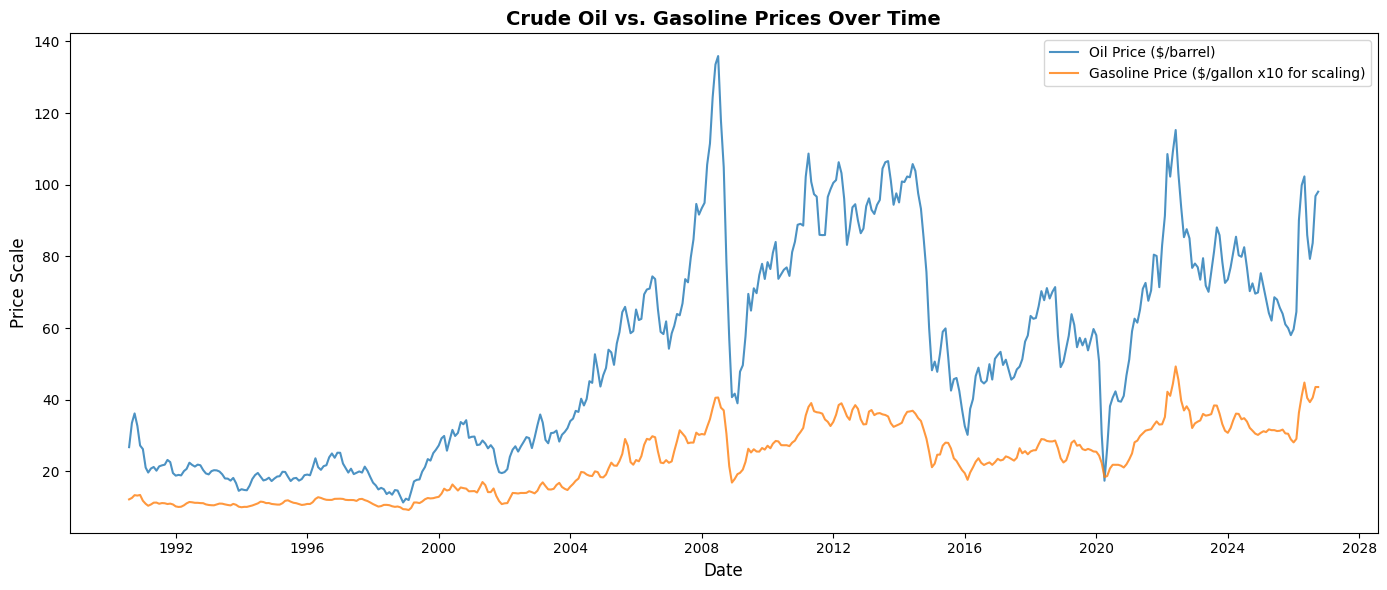

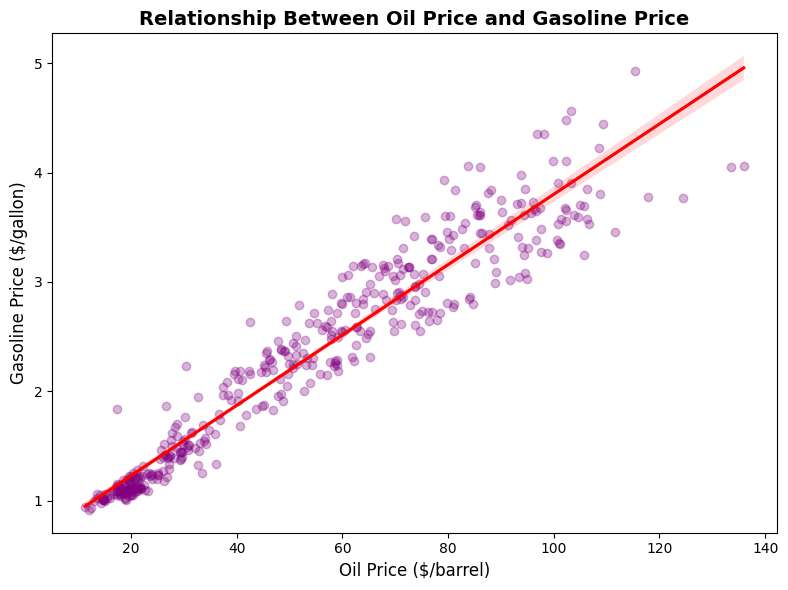

In [6]:
# summary statistics
print(monthly_merged[['Avg_Gas_Price', 'Avg_Oil_Price']].describe())

# calculate correlation coefficient
correlation = monthly_merged[['Avg_Gas_Price', 'Avg_Oil_Price']].corr().loc['Avg_Gas_Price', 'Avg_Oil_Price']
print(f'\nCorrelation coefficient: {correlation:.4f}')

# create line plot of gas/oil price vs. time
plt.figure(figsize=(14, 6))
plt.plot(
    monthly_merged['Date'],
    monthly_merged['Avg_Oil_Price'],
    label='Oil Price ($/barrel)',
    color='tab:blue',
    alpha=0.8,
)
plt.plot(
    monthly_merged['Date'],
    monthly_merged['Avg_Gas_Price'] * 10,
    label='Gasoline Price ($/gallon x10 for scaling)',
    color='tab:orange',
    alpha=0.8,
)
plt.title(
    'Crude Oil vs. Gasoline Prices Over Time',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price Scale', fontsize=12)
plt.legend()
plt.tight_layout()
plt.savefig('price_trends_timeseries.png', dpi=300)
plt.show()

# create scatter plot with regression line
plt.figure(figsize=(8, 6))
sns.regplot(
    data=monthly_merged,
    x='Avg_Oil_Price',
    y='Avg_Gas_Price',
    scatter_kws={'alpha': 0.3, 'color': 'purple'},
    line_kws={'color': 'red'},
)
plt.title('Relationship Between Oil Price and Gasoline Price', fontsize=14, fontweight='bold')
plt.xlabel('Oil Price ($/barrel)', fontsize=12)
plt.ylabel('Gasoline Price ($/gallon)', fontsize=12)
plt.tight_layout()
plt.savefig('oil_gas_scatter.png', dpi=300)
plt.show()

In [9]:
# apply natural log to the price columns
monthly_merged[['Log_Gas_Price', 'Log_Oil_Price']] = np.log(monthly_merged[['Avg_Gas_Price', 'Avg_Oil_Price']])

In [10]:
# export the dataframe to csv
monthly_merged.to_csv('log_monthly_oil_gas_prices.csv', index=False)